In [1]:
import csv
import json
from pathlib import Path
import joblib

import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import Markdown, display


current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in (current,) + tuple(current.parents)
        if (folder / "data" / "train" / "features.npy").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "No se encontro data/train/features.npy. "
        "Ejecuta primero python -m src.features."
    )

DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figs" / "clasificacion"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = (
    "BPSK", "QPSK", "8PSK",
    "16QAM", "64QAM", "16APSK", "ruido"
)

ESN0_LEVELS = np.arange(-10, 22, 2)
MODEL_SEED = 42


def save_figure(fig, name):
    fig.savefig(
        FIG_DIR / (name + ".png"),
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        FIG_DIR / (name + ".pdf"),
        bbox_inches="tight"
    )


print("Proyecto:", ROOT)
print("Figuras:", FIG_DIR)

Proyecto: /home/lcmj2803/coms_proyecto2
Figuras: /home/lcmj2803/coms_proyecto2/figs/clasificacion


In [2]:
def load_features(split):
    folder = DATA_DIR / split

    features = np.load(
        str(folder / "features.npy"),
        allow_pickle=False
    )

    with (folder / "features_info.json").open(
        "r", encoding="utf-8"
    ) as file:
        info = json.load(file)

    with (folder / "meta.csv").open(
        "r", newline="", encoding="utf-8"
    ) as file:
        metadata = list(csv.DictReader(file))

    columns = info["columns"]

    if features.ndim != 2 or features.shape[1] != len(columns):
        raise ValueError("Forma incorrecta de features en {}.".format(split))

    if len(features) != len(metadata):
        raise ValueError("Features y etiquetas no coinciden en {}.".format(split))

    if not np.all(np.isfinite(features)):
        raise ValueError("Features no finitas en {}.".format(split))

    labels = np.array([row["mod"] for row in metadata])
    esn0 = np.array([float(row["snr_db"]) for row in metadata])

    if set(labels) != set(CLASSES):
        raise ValueError("Se esperaban las siete clases en {}.".format(split))

    if not np.all(np.isfinite(esn0[labels != "ruido"])):
        raise ValueError("Es/N0 no valido en las señales de {}.".format(split))

    return features, labels, esn0, columns


F_train, y_train, esn0_train, columns_train = load_features("train")
F_val, y_val, esn0_val, columns_val = load_features("val")

if columns_train != columns_val:
    raise ValueError("Las columnas de train y val son diferentes.")

# C21 es aproximadamente 1 por la normalizacion: no aporta discriminacion.
selected_indices = [
    i for i, name in enumerate(columns_train)
    if name != "C21"
]

selected_names = [columns_train[i] for i in selected_indices]

X_train = F_train[:, selected_indices]
X_val = F_val[:, selected_indices]

print("Features utilizadas:", selected_names)
print("Train:", X_train.shape)
print("Val:", X_val.shape)

Features utilizadas: ['abs_C20', 'abs_C40', 'C42', 'abs_C60', 'C63']
Train: (56000, 5)
Val: (11200, 5)


In [3]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=MODEL_SEED,
    n_jobs=2
)

print("Entrenando con train...")
model.fit(X_train, y_train)

# Una prediccion por observacion de validacion.
y_pred = model.predict(X_val)

accuracy_global = accuracy_score(y_val, y_pred)

print("Entrenamiento terminado.")
print("Exactitud global en val: {:.2%}".format(accuracy_global))
print(
    "Aciertos: {} / {}".format(
        np.count_nonzero(y_pred == y_val),
        len(y_val)
    )
)

Entrenando con train...
Entrenamiento terminado.
Exactitud global en val: 36.26%
Aciertos: 4061 / 11200


Es/N0 (dB) | Observaciones | Exactitud
       -10 |           600 | 3.50%
        -8 |           600 | 4.17%
        -6 |           600 | 5.50%
        -4 |           600 | 7.00%
        -2 |           600 | 8.33%
         0 |           600 | 10.17%
         2 |           600 | 16.83%
         4 |           600 | 20.67%
         6 |           600 | 23.67%
         8 |           600 | 32.33%
        10 |           600 | 36.50%
        12 |           600 | 47.17%
        14 |           600 | 52.83%
        16 |           600 | 61.67%
        18 |           600 | 66.67%
        20 |           600 | 70.50%


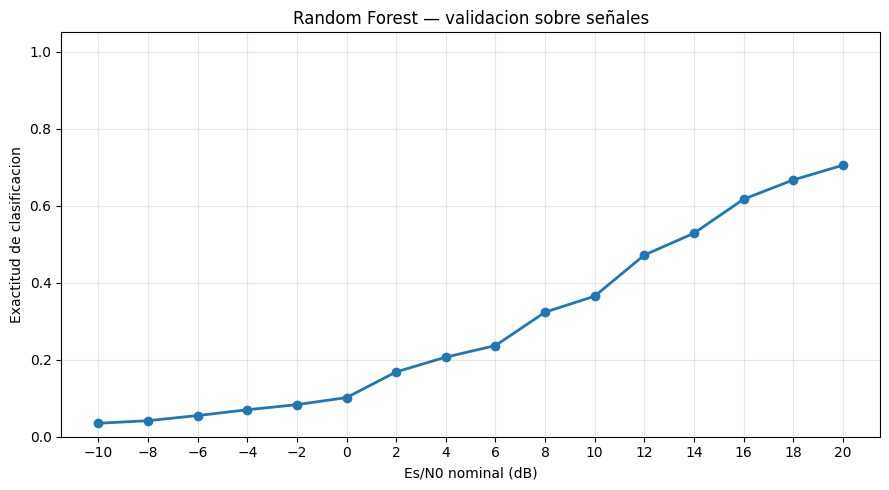

In [4]:
accuracy_by_esn0 = []

print("Es/N0 (dB) | Observaciones | Exactitud")

for level in ESN0_LEVELS:
    mask = (y_val != "ruido") & (esn0_val == level)
    count = int(np.count_nonzero(mask))

    if count != 600:
        raise ValueError(
            "Se esperaban 600 señales a {} dB; hay {}.".format(
                level, count
            )
        )

    accuracy = accuracy_score(y_val[mask], y_pred[mask])
    accuracy_by_esn0.append(accuracy)

    print(
        "{:>10} | {:>13} | {:.2%}".format(
            level, count, accuracy
        )
    )

accuracy_by_esn0 = np.asarray(accuracy_by_esn0)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    ESN0_LEVELS,
    accuracy_by_esn0,
    marker="o",
    linewidth=2
)

ax.set_xlabel("Es/N0 nominal (dB)")
ax.set_ylabel("Exactitud de clasificacion")
ax.set_title("Random Forest — validacion sobre señales")
ax.set_xticks(ESN0_LEVELS)
ax.set_ylim(0.0, 1.05)
ax.grid(alpha=0.3)

plt.tight_layout()
save_figure(fig, "01_exactitud_vs_esn0_val")
plt.show()

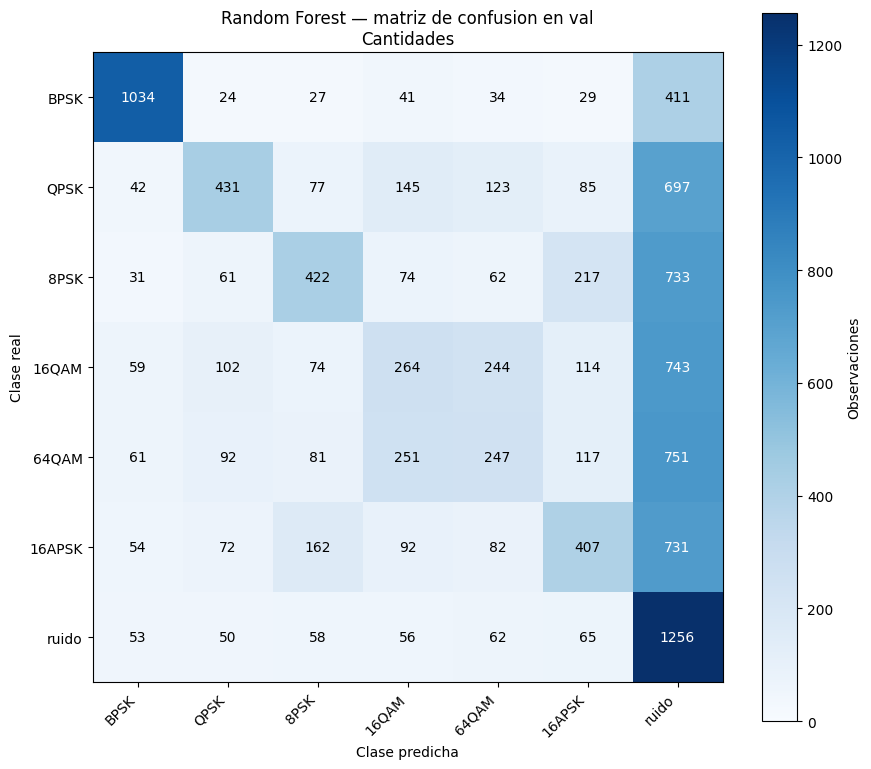

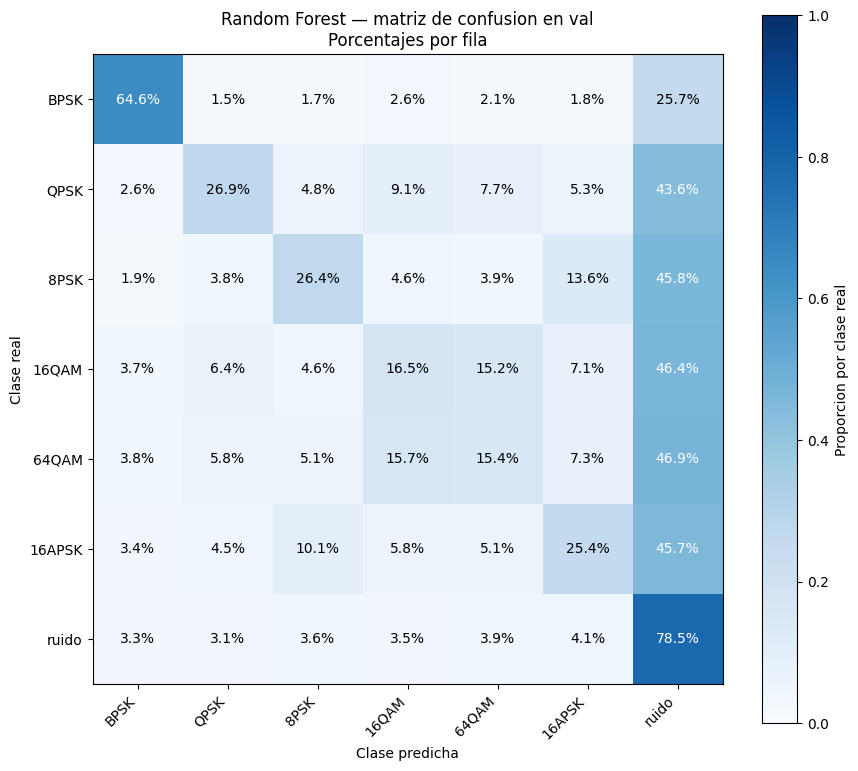

Matrices guardadas en: /home/lcmj2803/coms_proyecto2/figs/clasificacion


In [6]:
cm = confusion_matrix(
    y_val,
    y_pred,
    labels=list(CLASSES)
)

class_totals = cm.sum(axis=1)
cm_normalized = cm / class_totals[:, None].astype(np.float64)

versions = (
    (cm, False, "02_confusion_conteos_val"),
    (cm_normalized, True, "03_confusion_porcentajes_val"),
)

for matrix, normalized, filename in versions:
    fig, ax = plt.subplots(figsize=(9, 8))

    image = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=1.0 if normalized else None
    )

    fig.colorbar(
        image,
        ax=ax,
        label="Proporcion por clase real" if normalized else "Observaciones"
    )

    ticks = np.arange(len(CLASSES))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(
        "Random Forest — matriz de confusion en val"
        + ("\nPorcentajes por fila" if normalized else "\nCantidades")
    )

    threshold = matrix.max() / 2.0

    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            label = (
                "{:.1%}".format(matrix[i, j])
                if normalized
                else str(int(matrix[i, j]))
            )

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                color="white" if matrix[i, j] > threshold else "black"
            )

    plt.tight_layout()
    save_figure(fig, filename)
    plt.show()

print("Matrices guardadas en:", FIG_DIR)

In [7]:
recall_per_class = np.diag(cm_normalized)

best_index = int(np.argmax(recall_per_class))
worst_index = int(np.argmin(recall_per_class))

errors = cm.copy()
np.fill_diagonal(errors, 0)

comment = (
    "### Comentario de los resultados\n\n"
    "El Random Forest, entrenado exclusivamente con train, obtuvo "
    "una exactitud global de **{:.2%}** sobre las siete clases de val. "
    "Se utilizaron las cinco features no constantes.\n\n"
    "La clase con mayor proporción de aciertos fue **{} ({:.2%})** "
    "y la de menor proporción fue **{} ({:.2%})**.\n\n"
).format(
    accuracy_global,
    CLASSES[best_index],
    recall_per_class[best_index],
    CLASSES[worst_index],
    recall_per_class[worst_index]
)

if errors.max() > 0:
    real_index, predicted_index = np.unravel_index(
        np.argmax(errors), errors.shape
    )

    comment += (
        "Una de las confusiones más frecuentes fue **{} → {}**, "
        "con **{} observaciones**, equivalentes al **{:.2%}** "
        "de la clase real {}.\n\n"
    ).format(
        CLASSES[real_index],
        CLASSES[predicted_index],
        errors[real_index, predicted_index],
        cm_normalized[real_index, predicted_index],
        CLASSES[real_index]
    )
else:
    comment += "No se observaron errores de clasificación en val.\n\n"

comment += (
    "La exactitud sobre señales fue **{:.2%} a −10 dB** y "
    "**{:.2%} a +20 dB**. La curva por Es/N0 excluye las "
    "observaciones de ruido puro, pero cuenta como error una señal "
    "predicha como ruido.\n\n"
    "La matriz combina todos los niveles de Es/N0; por ello, una "
    "confusión global no demuestra que dos modulaciones sean "
    "indistinguibles a Es/N0 alto. Test permanece reservado para "
    "la evaluación final."
).format(
    accuracy_by_esn0[0],
    accuracy_by_esn0[-1]
)

display(Markdown(comment))

### Comentario de los resultados

El Random Forest, entrenado exclusivamente con train, obtuvo una exactitud global de **36.26%** sobre las siete clases de val. Se utilizaron las cinco features no constantes.

La clase con mayor proporción de aciertos fue **ruido (78.50%)** y la de menor proporción fue **64QAM (15.44%)**.

Una de las confusiones más frecuentes fue **64QAM → ruido**, con **751 observaciones**, equivalentes al **46.94%** de la clase real 64QAM.

La exactitud sobre señales fue **3.50% a −10 dB** y **70.50% a +20 dB**. La curva por Es/N0 excluye las observaciones de ruido puro, pero cuenta como error una señal predicha como ruido.

La matriz combina todos los niveles de Es/N0; por ello, una confusión global no demuestra que dos modulaciones sean indistinguibles a Es/N0 alto. Test permanece reservado para la evaluación final.

In [10]:
#carpeta nueva 
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True) # a model_dir se le crea su carpeta
MODEL_PATH = MODEL_DIR / "random_forest.joblib" #nombre del modelo 

#Predicciones originales como referencia
predictions_before = model.predict(X_val).copy()
correct_before = int(np.count_nonzero(predictions_before == y_val))

print(
    "Antes de Guardar:{} / {} = {:.2%}".format(
        correct_before,
        len(y_val),
        correct_before / float(len(y_val))
        
    )
)

#Guardar árboles y sus parámetros aprendidos 
joblib.dump(model, str(MODEL_PATH), compress=3)

print("Modelo en:",MODEL_PATH)



Antes de Guardar:4061 / 11200 = 36.26%
Modelo en: /home/lcmj2803/coms_proyecto2/models/random_forest.joblib


In [12]:
# Recuperar el modelo desde el archivo.
model_loaded = joblib.load(str(MODEL_PATH))

# Usar exactamente las mismas features de validacion y su mismo orden.
predictions_after = model_loaded.predict(X_val)

correct_after = int(np.count_nonzero(predictions_after == y_val))
accuracy_after = correct_after / float(len(y_val))

print(
    "Despues de cargar: {} / {} = {:.2%}".format(
        correct_after,
        len(y_val),
        accuracy_after
    )
)

# Comprobar cada prediccion, no solamente el porcentaje global.
np.testing.assert_array_equal(
    predictions_before,
    predictions_after,
    err_msg="Las predicciones cambiaron despues de guardar y cargar."
)

print("Correcto: todas las predicciones coinciden.")

# Comprobar tambien el resultado de referencia indicado en la imagen.
assert len(y_val) == 11200, \
    "Se esperaban 11200 observaciones de validacion."

assert correct_after == 4061, \
    "El resultado no coincide con la referencia de 4061 aciertos."

print("Correcto: se conserva la referencia de 4061 / 11200 = 36.26 %.")

Despues de cargar: 4061 / 11200 = 36.26%
Correcto: todas las predicciones coinciden.
Correcto: se conserva la referencia de 4061 / 11200 = 36.26 %.
